# Bike-Sharing Demand Forecasting

**Question:** How many bikes will be rented in a given hour?

A bike-sharing company needs enough bikes at its stations when people want them, and needs to plan maintenance and staff when demand is low. Predicting hourly demand from the time, the day and the weather helps it do both.

**Data:** 17,379 hours of rentals from Capital Bikeshare in Washington DC, 2011–2012, with weather for each hour.
Source: Fanaee-T & Gama (2013), *Event labeling combining ensemble detectors and background knowledge*, Progress in Artificial Intelligence. Original data from the UCI Machine Learning Repository; downloaded here from Udacity's public course repository.

**This is a regression problem:** the model predicts a number (bikes per hour), not a yes/no answer.

**Steps:** 1) load and check the data · 2) explore it · 3) split by time · 4) baselines · 5) three models · 6) cross-validation and tuning · 7) final test and error analysis · 8) conclusions

## 1. Load and check the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/udacity/deep-learning-v2-pytorch/master/project-bikesharing/Bike-Sharing-Dataset/hour.csv"
df = pd.read_csv(url, parse_dates=["dteday"])

print("Rows, columns:", df.shape)
print("From", df["dteday"].min().date(), "to", df["dteday"].max().date())
df.head()

Rows, columns: (17379, 17)
From 2011-01-01 to 2012-12-31


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Main columns: `hr` (hour 0–23), `workingday` (1 = not a weekend or holiday), `weathersit` (1 = clear … 4 = heavy rain/snow), `temp` (temperature, scaled to 0–1), `hum` (humidity), `windspeed`, and the target **`cnt`** = number of bikes rented in that hour.

In [2]:
print("Missing values:", df.isna().sum().sum())
print("Does casual + registered always equal cnt?", (df["casual"] + df["registered"] == df["cnt"]).all())
df["cnt"].describe().round(1)

Missing values: 0
Does casual + registered always equal cnt? True


count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: cnt, dtype: float64

No missing values. Rentals per hour range from 1 to 977, with an average of about 189.

⚠️ **Data leakage:** `casual` and `registered` add up exactly to `cnt`, our target. They are only known *after* the hour is over, so we must not use them as inputs. `instant` (a row number) and `dteday` (the date) are also left out of the model.

In [3]:
# The temperature is stored on a 0-1 scale. The dataset documentation gives the formula
# to convert it back to degrees Celsius (min -8 °C, max 39 °C). We use it only for charts.
df["temp_c"] = df["temp"] * 47 - 8
df["temp_c"].describe().round(1)

count    17379.0
mean        15.4
std          9.1
min         -7.1
25%          8.0
50%         15.5
75%         23.0
max         39.0
Name: temp_c, dtype: float64

## 2. Explore the data

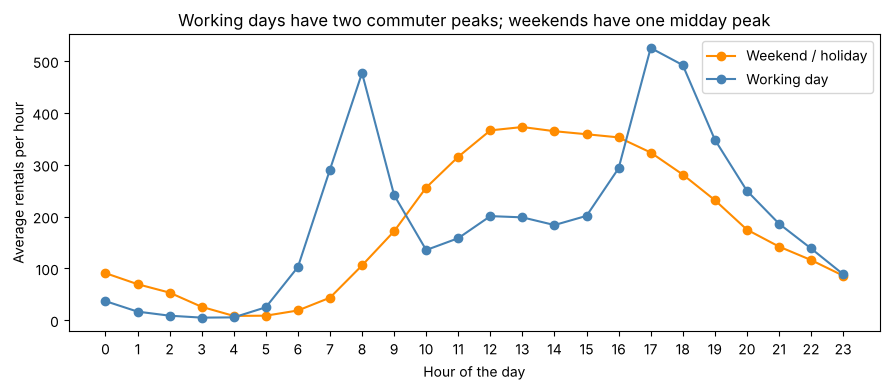

,Weekend / holiday,Working day
hr,,
3,26.0,5.0
8,106.0,477.0
13,373.0,198.0
17,324.0,525.0


In [4]:
hourly = df.groupby(["hr", "workingday"])["cnt"].mean().unstack()
hourly.columns = ["Weekend / holiday", "Working day"]

hourly.plot(figsize=(9, 4), marker="o", color=["darkorange", "steelblue"])
plt.xlabel("Hour of the day")
plt.ylabel("Average rentals per hour")
plt.title("Working days have two commuter peaks; weekends have one midday peak")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("demand_by_hour.png", dpi=150)
plt.show()

hourly.loc[[3, 8, 13, 17]].round(0)

We observe that the daily pattern is completely different on working days and on weekends. On working days, demand peaks at 8:00 (477 rentals) and 17:00 (525), when people commute. On weekends there is one broad peak around midday (373 at 13:00), and almost no one rides at 8:00. **So the model needs to combine hour *and* type of day.** A simple model that adds up separate effects can't capture this.

temp_c
below 0     57.0
0-10       113.0
10-20      188.0
20-30      256.0
30+        326.0
Name: cnt, dtype: float64


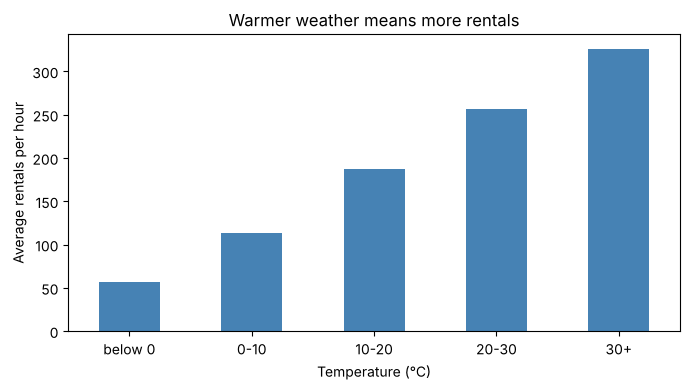

In [5]:
temp_groups = pd.cut(df["temp_c"], bins=[-10, 0, 10, 20, 30, 40],
                     labels=["below 0", "0-10", "10-20", "20-30", "30+"])
by_temp = df.groupby(temp_groups, observed=True)["cnt"].mean()
print(by_temp.round(0))

by_temp.plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.xlabel("Temperature (°C)")
plt.ylabel("Average rentals per hour")
plt.title("Warmer weather means more rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("demand_by_temperature.png", dpi=150)
plt.show()

We observe that demand rises steadily with temperature: from 57 rentals per hour below 0 °C to 326 above 30 °C, nearly six times more.

In [6]:
df.groupby("weathersit")["cnt"].agg(["count", "mean"]).round(0)

,count,mean
weathersit,,
1,11413,205.0
2,4544,175.0
3,1419,112.0
4,3,74.0


We observe that rain and snow cut demand. Clear hours average 205 rentals, light rain or snow (category 3) only 112. Category 4 (heavy rain/snow) has just 3 hours in the whole dataset, too few to learn anything from.

In [7]:
df.groupby("yr")["cnt"].mean().round(0).rename(index={0: 2011, 1: 2012})

yr
2011    144.0
2012    235.0
Name: cnt, dtype: float64

We observe that the service grew fast: average hourly rentals rose from 144 in 2011 to 235 in 2012, about 63% more. The model needs the year (`yr`) to capture this growth.

## 3. Split the data by time

In the hotel project we split the data randomly. **For forecasting, that would be cheating:** the model would train on hours *after* the ones it's tested on. In real life we always predict the future from the past.

So we train on everything before **1 September 2012** and test on the last four months (September–December 2012).

In [8]:
features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
            "weathersit", "temp", "atemp", "hum", "windspeed"]

train = df[df["dteday"] < "2012-09-01"]
test  = df[df["dteday"] >= "2012-09-01"]

X_train, y_train = train[features], train["cnt"]
X_test,  y_test  = test[features],  test["cnt"]
print("Training hours:", len(train), "| Test hours:", len(test))

Training hours: 14491 | Test hours: 2888


## 4. Baselines

We measure every model with three numbers:
- **MAE** (mean absolute error): on average, how many bikes off are we? Lower is better.
- **RMSE** (root mean squared error): like MAE, but punishes big misses more. Lower is better.
- **R²**: the share of the variation in demand that the model explains. 1 = perfect, 0 = no better than always guessing the average.

A model is only useful if it beats simple rules. We try two:
1. always predict the training average;
2. predict the average for **that hour on that type of day**, a rule a manager could use without any machine learning.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(name, predictions):
    return {"model": name,
            "MAE":  round(mean_absolute_error(y_test, predictions), 1),
            "RMSE": round(mean_squared_error(y_test, predictions) ** 0.5, 1),
            "R2":   round(r2_score(y_test, predictions), 3)}

results = []

# Baseline 1: the overall average
results.append(evaluate("Baseline: overall average", np.full(len(y_test), y_train.mean())))

# Baseline 2: average for each (working day, hour) combination
profile = train.groupby(["workingday", "hr"])["cnt"].mean().rename("prediction").reset_index()
pred_profile = test.merge(profile, on=["workingday", "hr"], how="left")["prediction"].values
results.append(evaluate("Baseline: average by hour & day type", pred_profile))

pd.DataFrame(results)

,model,MAE,RMSE,R2
0,Baseline: overall average,170.5,226.0,-0.078
1,Baseline: average by hour & day type,94.8,138.5,0.595


The simple hour-and-day rule already explains about 60% of the variation (R² 0.595), and is off by about 95 bikes per hour on average. That's the bar our models have to beat.

(The overall-average baseline has a slightly *negative* R². The test period comes from busy 2012, so the 2011–2012 average is too low for it.)

## 5. Three models

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

# Linear regression: treat hour, month, weekday, season and weather as categories (one-hot encoding)
categorical = ["season", "mnth", "hr", "weekday", "weathersit"]
encode = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), categorical)],
                           remainder="passthrough")
linear = make_pipeline(encode, LinearRegression())
linear.fit(X_train, y_train)
results.append(evaluate("Linear regression", linear.predict(X_test)))

In [11]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)
results.append(evaluate("Random forest", forest.predict(X_test)))

boosting = HistGradientBoostingRegressor(random_state=42)
boosting.fit(X_train, y_train)
results.append(evaluate("Gradient boosting", boosting.predict(X_test)))

pd.DataFrame(results)

,model,MAE,RMSE,R2
0,Baseline: overall average,170.5,226.0,-0.078
1,Baseline: average by hour & day type,94.8,138.5,0.595
2,Linear regression,97.4,132.3,0.630
3,Random forest,48.1,73.5,0.886
4,Gradient boosting,45.7,68.7,0.900


Linear regression barely beats the simple rule (R² 0.63). It adds up the effect of the hour and the effect of the day type separately, so it can't learn that 8:00 is busy on working days but quiet on weekends.

The two tree-based models learn these combinations by themselves. Their average error falls to about 46–48 bikes per hour, half that of the baseline, and they explain about 89–90% of the variation.

## 6. Cross-validation and tuning

So far we've tried each model once. Before choosing settings, we check how stable the model is by training and testing it several times **inside the training data**, always training on the past and testing on the next period (`TimeSeriesSplit`). The real test set stays untouched until the very end.

In [12]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

time_cv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(HistGradientBoostingRegressor(random_state=42), X_train, y_train,
                         cv=time_cv, scoring="neg_mean_absolute_error")
print("MAE in each fold:", (-scores).round(1))
print("Average MAE:", round(-scores.mean(), 1))

MAE in each fold: [60.2 29.5 49.7 63.2 44.7]
Average MAE: 49.5


The error changes a lot depending on which period is tested (about 30 to 63 bikes). Each fold also trains on a different amount of history. So a model's score depends on the period you test it on, and one test score alone can be misleading.

In [13]:
from sklearn.model_selection import GridSearchCV

# Try 6 combinations of two settings and keep the one with the lowest cross-validated MAE (~30-60 seconds)
param_grid = {"learning_rate": [0.05, 0.1],
              "max_leaf_nodes": [15, 31, 63]}
search = GridSearchCV(HistGradientBoostingRegressor(random_state=42, max_iter=500),
                      param_grid, cv=time_cv, scoring="neg_mean_absolute_error")
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Cross-validated MAE:", round(-search.best_score_, 1))

Best settings: {'learning_rate': 0.1, 'max_leaf_nodes': 15}
Cross-validated MAE: 47.6


## 7. Final test and error analysis

In [14]:
best_model = search.best_estimator_
pred_best = best_model.predict(X_test)

# A model can't rent out a negative number of bikes: round negative predictions up to 0
print("Negative predictions:", (pred_best < 0).sum())
pred_best = np.clip(pred_best, 0, None)

results.append(evaluate("Gradient boosting (tuned)", pred_best))
final = pd.DataFrame(results)
final

Negative predictions: 19


,model,MAE,RMSE,R2
0,Baseline: overall average,170.5,226.0,-0.078
1,Baseline: average by hour & day type,94.8,138.5,0.595
2,Linear regression,97.4,132.3,0.630
3,Random forest,48.1,73.5,0.886
4,Gradient boosting,45.7,68.7,0.900
5,Gradient boosting (tuned),45.0,68.1,0.902


Tuning gives only a small gain over the default settings (MAE 45.7 → 45.0). The big improvement came from choosing a model that can learn combinations, not from fine-tuning it. The final model is off by **about 45 bikes per hour on average**, when the test period averages about 240 rentals per hour, and it explains **90%** of the variation.

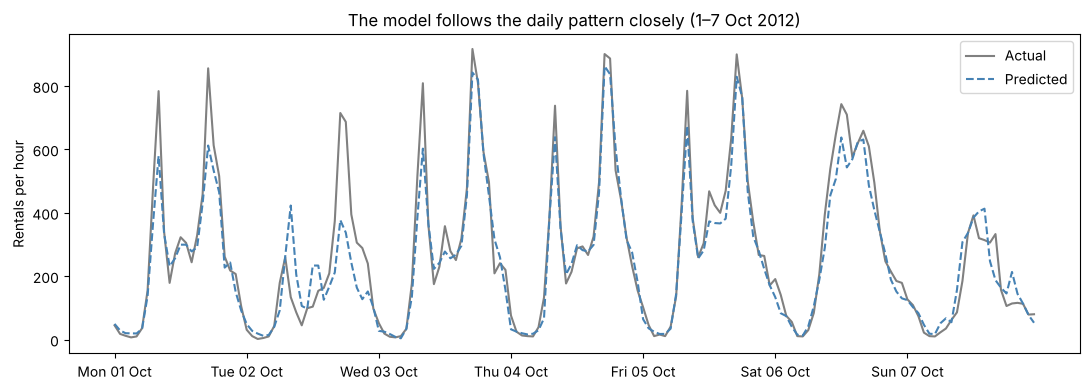

In [15]:
week = test[(test["dteday"] >= "2012-10-01") & (test["dteday"] < "2012-10-08")]
week_pred = np.clip(best_model.predict(week[features]), 0, None)

plt.figure(figsize=(11, 4))
plt.plot(range(len(week)), week["cnt"].values, label="Actual", color="grey")
plt.plot(range(len(week)), week_pred, label="Predicted", color="steelblue", ls="--")
plt.xticks(range(0, len(week), 24), week["dteday"].dt.strftime("%a %d %b").iloc[::24])
plt.ylabel("Rentals per hour")
plt.title("The model follows the daily pattern closely (1–7 Oct 2012)")
plt.legend()
plt.tight_layout()
plt.savefig("actual_vs_predicted_week.png", dpi=150)
plt.show()

hr
17    106.0
8     101.0
18     94.0
16     72.0
Name: error, dtype: float64


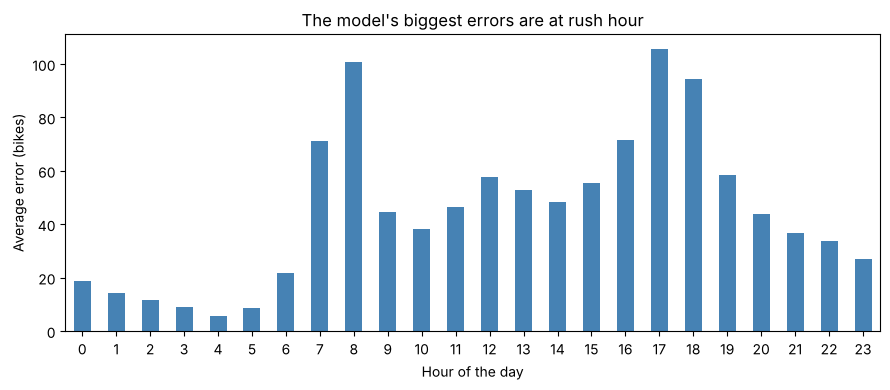

In [16]:
error_by_hour = (test.assign(error=np.abs(y_test - pred_best))
                     .groupby("hr")["error"].mean())
print(error_by_hour.sort_values(ascending=False).head(4).round(0))

error_by_hour.plot(kind="bar", color="steelblue", figsize=(9, 4))
plt.xlabel("Hour of the day")
plt.ylabel("Average error (bikes)")
plt.title("The model's biggest errors are at rush hour")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("error_by_hour.png", dpi=150)
plt.show()

We observe that the largest errors come at the commuter peaks: about 106 bikes at 17:00 and 101 at 8:00, against much smaller errors at night. Those are the hours with the most bikes, and the hours when running out of bikes would hurt the business most.

### What does the model rely on?
**Permutation importance:** shuffle one column in the test data and see how much worse the predictions get. The bigger the increase in error, the more the model relies on that column.

hr            146.6
workingday     32.6
temp           17.6
weekday         7.9
hum             6.9
atemp           6.6
weathersit      4.0
mnth            3.2
season          3.0
holiday         0.5
windspeed       0.3
yr              0.0
dtype: float64


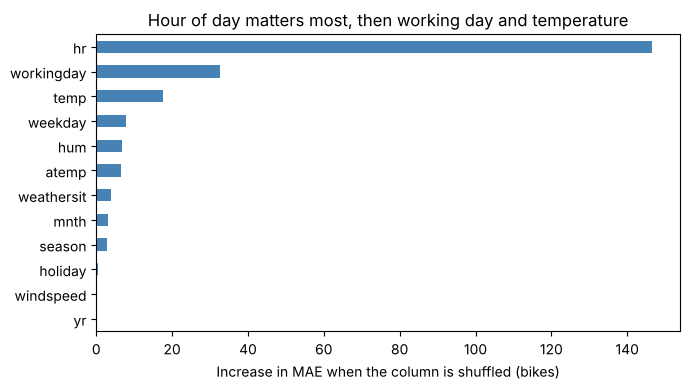

In [17]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=42,
                              scoring="neg_mean_absolute_error")
importance = pd.Series(perm.importances_mean, index=features).sort_values()
print(importance.sort_values(ascending=False).round(1))

importance.plot(kind="barh", color="steelblue", figsize=(7, 4))
plt.xlabel("Increase in MAE when the column is shuffled (bikes)")
plt.title("Hour of day matters most, then working day and temperature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

We observe that the hour of the day matters most by far: shuffling it adds about 147 bikes to the average error. Next come working day (about 33) and temperature (about 18). This matches what we saw in the exploration.

Note: `yr` shows 0 here. That's not because it's useless. Every test hour is in 2012, so shuffling the year within the test set changes nothing.

## 8. Conclusions

1. **What drives demand:** bike rentals follow people's routines and the weather. On working days there are two commuter peaks (8:00 and 17:00); on weekends there is one midday peak. Warm, dry weather brings many more riders, and the service grew about 63% from 2011 to 2012.

2. **How good is the model?** The tuned gradient boosting model is off by about 45 bikes per hour on average and explains 90% of the variation in demand. That's twice as accurate as a simple "average for this hour and day type" rule (95 bikes off, 60% explained).

3. **What I learned about modelling:**
   - For forecasting, the data must be split by time, not randomly.
   - Always compare with simple baselines. A good-looking R² means little on its own.
   - Choosing a model that can learn combinations (hour × day type) mattered far more than tuning settings.

4. **How the company could use it:** predict demand for the next day using the weather forecast, then move bikes to busy stations before the morning and evening peaks, and schedule maintenance for quiet night hours.

5. **Limitations:** two years of data from one city. The model predicts total demand for the whole city, not per station. It relies on actual weather, whereas in real use it would only have a weather *forecast*, which is less accurate. Its largest errors are at rush hour, exactly when accuracy matters most.

6. **What I would try next:** add recent demand (e.g. rentals in the same hour yesterday) as an input; predict casual and registered users separately; test the model on more recent data.